# Notebook 06: Microgrid Operation Optimization
## Graduation Thesis: CNN-BiLSTM-Attention Model for Electricity Load Forecasting in a Microgrid

**Contents:**
1. Microgrid Modeling (Solar PV, Battery, Diesel Generator, Utility Grid)
2. Linear Programming (LP) for Optimal Operation Scheduling
3. Run Optimization Using Load Forecasts from Different Models
4. Compare Operating Costs
5. Detailed Operational Analysis & Battery Control Strategies
6. Economic Performance Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, warnings
from scipy.optimize import linprog

warnings.filterwarnings('ignore')
plt.rcParams['font.size'] = 12
plt.rcParams['axes.grid'] = True

PROJECT_DIR = os.getcwd()
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')

# Load predictions
baseline_pred = np.load(os.path.join(RESULTS_DIR, 'baseline_predictions.npz'))
advanced_pred = np.load(os.path.join(RESULTS_DIR, 'advanced_predictions.npz'))
proposed_pred = np.load(os.path.join(RESULTS_DIR, 'proposed_predictions.npz'))

y_true = proposed_pred['y_true']

all_predictions = {
    'CNN-BiLSTM-Attention': proposed_pred['y_pred'],
    'LSTM': baseline_pred['y_pred_lstm'],
    'GRU': baseline_pred['y_pred_gru'],
    'BiLSTM': advanced_pred['y_pred_bilstm'],
    'CNN-LSTM': advanced_pred['y_pred_cnn_lstm'],
}

print(f'Test samples: {len(y_true)}')
print(f'Test days: {len(y_true) // 24}')
print(f'Load range: {y_true.min():.0f} - {y_true.max():.0f} kW')

Test samples: 2559
Test days: 106
Load range: 2591 - 4939 kW


## 1. Mô hình hóa Microgrid

**Thành phần Microgrid Campus:**
- Solar PV (pin mặt trời): công suất phụ thuộc bức xạ, miễn phí
- Battery (pin lưu trữ): sạc/xả linh hoạt, tối ưu TOU
- Diesel Generator: nguồn dự phòng, chi phí cao
- Grid Connection: mua/bán điện từ lưới, giá TOU

In [2]:
# === THÔNG SỐ MICROGRID CAMPUS ===
# (Scale phù hợp campus ~3000-5000 kW)

# Solar PV
SOLAR_CAPACITY = 500  # kW peak
solar_profile = np.array([
    0, 0, 0, 0, 0, 0.05,           # 0h-5h
    0.15, 0.35, 0.55, 0.75, 0.90, 0.95,  # 6h-11h
    1.0, 0.95, 0.85, 0.70, 0.50, 0.25,   # 12h-17h
    0.08, 0, 0, 0, 0, 0             # 18h-23h
])
P_solar = SOLAR_CAPACITY * solar_profile  # kW

# Diesel Generator
DIESEL_MAX = 800    # kW
DIESEL_COST = 0.25  # $/kWh

# Battery
BATTERY_CAPACITY = 1000  # kWh
BATTERY_MAX_POWER = 300  # kW (max charge/discharge)
SOC_MIN = 0.2
SOC_MAX = 0.9
SOC_INIT = 0.5
BATTERY_EFF = 0.95
BATTERY_COST = 0.02  # $/kWh (wear cost)

# Grid (TOU pricing)
grid_buy_price = np.array([
    0.06, 0.06, 0.06, 0.06, 0.06, 0.06,   # 0h-5h: off-peak
    0.10, 0.10, 0.12, 0.15, 0.18, 0.20,    # 6h-11h: shoulder->peak
    0.22, 0.22, 0.20, 0.18, 0.15, 0.12,    # 12h-17h: peak->shoulder
    0.15, 0.18, 0.20, 0.15, 0.10, 0.08     # 18h-23h: evening peak->off
])
grid_sell_price = grid_buy_price * 0.7
GRID_MAX = 5000  # kW max buy/sell

print('=== THÔNG SỐ MICROGRID CAMPUS ===')
print(f'Solar PV: {SOLAR_CAPACITY} kW peak')
print(f'Diesel: max {DIESEL_MAX} kW, {DIESEL_COST} $/kWh')
print(f'Battery: {BATTERY_CAPACITY} kWh, max {BATTERY_MAX_POWER} kW')
print(f'Grid: max {GRID_MAX} kW, TOU {grid_buy_price.min():.2f}-{grid_buy_price.max():.2f} $/kWh')

=== THÔNG SỐ MICROGRID CAMPUS ===
Solar PV: 500 kW peak
Diesel: max 800 kW, 0.25 $/kWh
Battery: 1000 kWh, max 300 kW
Grid: max 5000 kW, TOU 0.06-0.22 $/kWh


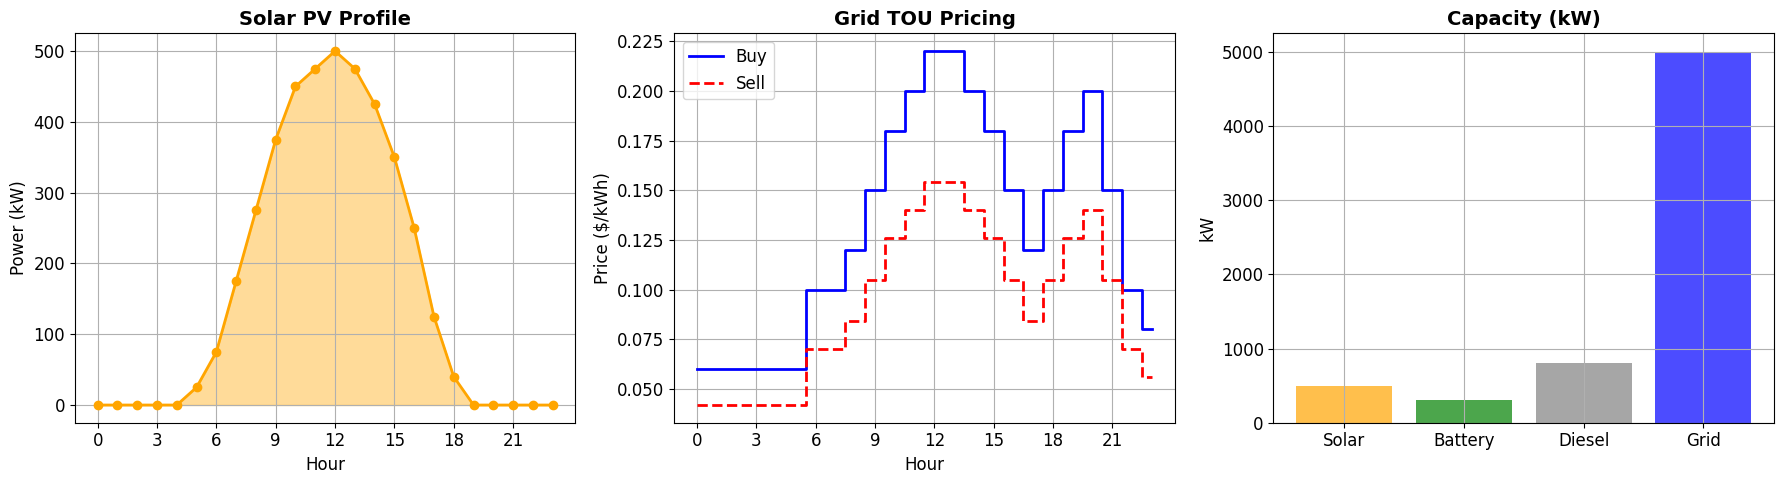

In [3]:
# Visualize microgrid parameters
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
hours = range(24)

axes[0].fill_between(hours, P_solar, alpha=0.4, color='orange')
axes[0].plot(hours, P_solar, 'o-', color='orange', linewidth=2)
axes[0].set_title('Solar PV Profile', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Power (kW)')
axes[0].set_xticks(range(0, 24, 3))

axes[1].step(hours, grid_buy_price, 'b-', linewidth=2, label='Buy', where='mid')
axes[1].step(hours, grid_sell_price, 'r--', linewidth=2, label='Sell', where='mid')
axes[1].set_title('Grid TOU Pricing', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Hour')
axes[1].set_ylabel('Price ($/kWh)')
axes[1].legend()
axes[1].set_xticks(range(0, 24, 3))

axes[2].bar(['Solar', 'Battery', 'Diesel', 'Grid'],
            [SOLAR_CAPACITY, BATTERY_MAX_POWER, DIESEL_MAX, GRID_MAX],
            color=['orange', 'green', 'gray', 'blue'], alpha=0.7)
axes[2].set_title('Capacity (kW)', fontsize=14, fontweight='bold')
axes[2].set_ylabel('kW')

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'microgrid_params.png'), dpi=150)
plt.show()

## 2. Bài toán tối ưu

**Biến quyết định** (tại mỗi giờ t):
- $P_{diesel}(t)$: Công suất diesel
- $P_{grid\_buy}(t)$: Công suất mua từ lưới
- $P_{grid\_sell}(t)$: Công suất bán cho lưới
- $P_{bat\_charge}(t)$: Công suất sạc pin
- $P_{bat\_discharge}(t)$: Công suất xả pin

**Hàm mục tiêu:** Min tổng chi phí vận hành 24h

**Ràng buộc:**
- Cân bằng công suất: Solar + Diesel + Grid_buy + Bat_discharge = Load + Grid_sell + Bat_charge
- SOC pin: $SOC_{min} \leq SOC(t) \leq SOC_{max}$
- Giới hạn công suất: $0 \leq P_i(t) \leq P_{i,max}$

In [4]:
def optimize_microgrid_24h(P_load_24h, P_solar_24h):
    """LP optimization for 24h microgrid operation."""
    T = 24
    n_vars = 5 * T  # diesel, grid_buy, grid_sell, bat_charge, bat_discharge

    # Objective: minimize cost
    c = np.zeros(n_vars)
    for t in range(T):
        c[t]         = DIESEL_COST
        c[T + t]     = grid_buy_price[t]
        c[2*T + t]   = -grid_sell_price[t]
        c[3*T + t]   = BATTERY_COST
        c[4*T + t]   = BATTERY_COST

    # Equality: power balance
    A_eq = np.zeros((T, n_vars))
    b_eq = np.zeros(T)
    for t in range(T):
        A_eq[t, t]       = 1     # diesel
        A_eq[t, T + t]   = 1     # grid_buy
        A_eq[t, 2*T + t] = -1    # -grid_sell
        A_eq[t, 3*T + t] = -1    # -bat_charge
        A_eq[t, 4*T + t] = 1     # bat_discharge
        b_eq[t] = P_load_24h[t] - P_solar_24h[t]

    # Inequality: SOC constraints
    A_ub_list = []
    b_ub_list = []
    for t in range(T):
        # SOC(t) <= SOC_MAX
        row = np.zeros(n_vars)
        for s in range(t + 1):
            row[3*T + s] = BATTERY_EFF / BATTERY_CAPACITY
            row[4*T + s] = -1 / (BATTERY_EFF * BATTERY_CAPACITY)
        A_ub_list.append(row)
        b_ub_list.append(SOC_MAX - SOC_INIT)

        # SOC(t) >= SOC_MIN
        row2 = np.zeros(n_vars)
        for s in range(t + 1):
            row2[3*T + s] = -BATTERY_EFF / BATTERY_CAPACITY
            row2[4*T + s] = 1 / (BATTERY_EFF * BATTERY_CAPACITY)
        A_ub_list.append(row2)
        b_ub_list.append(SOC_INIT - SOC_MIN)

    A_ub = np.array(A_ub_list)
    b_ub = np.array(b_ub_list)

    # Bounds
    bounds = ([(0, DIESEL_MAX)] * T +
              [(0, GRID_MAX)] * T +
              [(0, GRID_MAX)] * T +
              [(0, BATTERY_MAX_POWER)] * T +
              [(0, BATTERY_MAX_POWER)] * T)

    result = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq,
                     bounds=bounds, method='highs')

    if result.success:
        x = result.x
        P_diesel = x[:T]
        P_grid_buy = x[T:2*T]
        P_grid_sell = x[2*T:3*T]
        P_bat_charge = x[3*T:4*T]
        P_bat_discharge = x[4*T:5*T]

        soc = np.zeros(T + 1)
        soc[0] = SOC_INIT
        for t in range(T):
            soc[t+1] = soc[t] + (P_bat_charge[t] * BATTERY_EFF - P_bat_discharge[t] / BATTERY_EFF) / BATTERY_CAPACITY

        return {
            'success': True,
            'total_cost': result.fun,
            'cost_diesel': np.sum(P_diesel * DIESEL_COST),
            'cost_grid_buy': np.sum(P_grid_buy * grid_buy_price),
            'revenue_grid_sell': np.sum(P_grid_sell * grid_sell_price),
            'cost_battery': np.sum((P_bat_charge + P_bat_discharge) * BATTERY_COST),
            'P_diesel': P_diesel, 'P_grid_buy': P_grid_buy,
            'P_grid_sell': P_grid_sell, 'P_bat_charge': P_bat_charge,
            'P_bat_discharge': P_bat_discharge, 'SOC': soc,
            'P_load': P_load_24h, 'P_solar': P_solar_24h,
        }
    else:
        return {'success': False}

print('LP optimizer ready!')

LP optimizer ready!


## 3. Chạy tối ưu với dự báo từ các models

In [5]:
# Run optimization for all models
cost_results = {}
n_days = min(30, len(y_true) // 24)
print(f'Evaluating {n_days} days...\n')

# Perfect forecast
perfect_costs = []
result_perfect_days = []
for day in range(n_days):
    s = day * 24
    load = y_true[s:s+24]
    if len(load) < 24: break
    res = optimize_microgrid_24h(load, P_solar)
    if res['success']:
        perfect_costs.append(res['total_cost'])
        result_perfect_days.append(res)
cost_results['Perfect Forecast'] = np.mean(perfect_costs)
print(f'Perfect Forecast: ${np.mean(perfect_costs):.2f}/day')

# All models
model_day_results = {}
for name, preds in all_predictions.items():
    model_costs = []
    day_results = []
    for day in range(n_days):
        s = day * 24
        load_forecast = preds[s:s+24]
        load_actual = y_true[s:s+24]
        if len(load_forecast) < 24: break

        # Optimize based on FORECAST
        res = optimize_microgrid_24h(load_forecast, P_solar)
        if res['success']:
            # Penalty for forecast error
            load_diff = load_actual - load_forecast
            base_cost = res['total_cost']
            penalty = 0
            for t in range(24):
                if load_diff[t] > 0:
                    penalty += load_diff[t] * grid_buy_price[t] * 1.5
                else:
                    penalty += abs(load_diff[t]) * grid_sell_price[t] * 0.5
            res['actual_cost'] = base_cost + penalty
            model_costs.append(res['actual_cost'])
            day_results.append(res)

    if model_costs:
        cost_results[name] = np.mean(model_costs)
        model_day_results[name] = day_results
        print(f'{name:25s}: ${np.mean(model_costs):.2f}/day')

print('\nDone!')

Evaluating 30 days...

Perfect Forecast: $10034.93/day
CNN-BiLSTM-Attention     : $10116.55/day
LSTM                     : $10127.90/day


GRU                      : $10269.59/day
BiLSTM                   : $10127.10/day
CNN-LSTM                 : $10229.52/day

Done!


## 4. So sánh chi phí vận hành

In [6]:
# Cost comparison table
cost_df = pd.DataFrame({
    'Model': list(cost_results.keys()),
    'Avg Cost/day ($)': list(cost_results.values()),
    'Avg Cost/month ($)': [v * 30 for v in cost_results.values()],
    'Avg Cost/year ($)': [v * 365 for v in cost_results.values()],
})

perfect_cost = cost_results['Perfect Forecast']
cost_df['Diff vs Perfect ($)'] = cost_df['Avg Cost/day ($)'] - perfect_cost
cost_df['Diff (%)'] = (cost_df['Diff vs Perfect ($)'] / perfect_cost * 100)
cost_df.to_csv(os.path.join(RESULTS_DIR, 'microgrid_cost_results.csv'), index=False)
print(cost_df.to_string(index=False))

               Model  Avg Cost/day ($)  Avg Cost/month ($)  Avg Cost/year ($)  Diff vs Perfect ($)  Diff (%)
    Perfect Forecast      10034.926530       301047.795907       3.662748e+06             0.000000  0.000000
CNN-BiLSTM-Attention      10116.553591       303496.607726       3.692542e+06            81.627061  0.813430
                LSTM      10127.901951       303837.058544       3.696684e+06            92.975421  0.926518
                 GRU      10269.593568       308087.807034       3.748402e+06           234.667038  2.338503
              BiLSTM      10127.103533       303813.105980       3.696393e+06            92.177002  0.918562
            CNN-LSTM      10229.520733       306885.621980       3.733775e+06           194.594202  1.939169


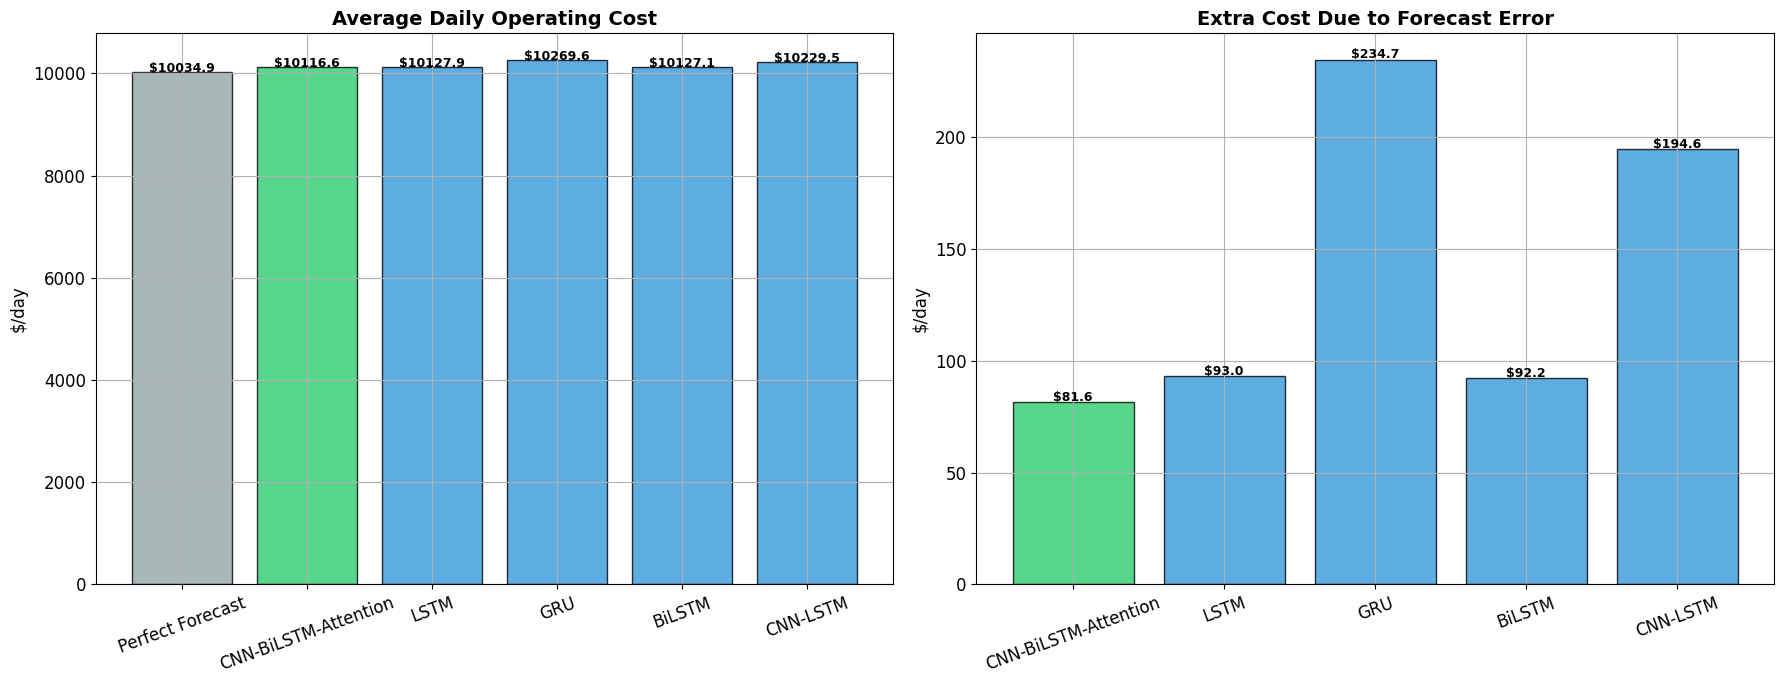

In [7]:
# Cost comparison charts
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

models = list(cost_results.keys())
costs = list(cost_results.values())
colors = ['#2ecc71' if 'Attention' in m else '#95a5a6' if 'Perfect' in m else '#3498db' for m in models]

bars = axes[0].bar(models, costs, color=colors, edgecolor='black', alpha=0.8)
axes[0].set_title('Average Daily Operating Cost', fontsize=14, fontweight='bold')
axes[0].set_ylabel('$/day')
for bar, c in zip(bars, costs):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                f'${c:.1f}', ha='center', fontweight='bold', fontsize=9)
axes[0].tick_params(axis='x', rotation=20)

# Extra cost vs perfect
model_names = [m for m in models if m != 'Perfect Forecast']
extra = [cost_results[m] - perfect_cost for m in model_names]
colors2 = ['#2ecc71' if 'Attention' in m else '#3498db' for m in model_names]
bars2 = axes[1].bar(model_names, extra, color=colors2, edgecolor='black', alpha=0.8)
axes[1].set_title('Extra Cost Due to Forecast Error', fontsize=14, fontweight='bold')
axes[1].set_ylabel('$/day')
for bar, c in zip(bars2, extra):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f'${c:.1f}', ha='center', fontweight='bold', fontsize=9)
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'microgrid_cost_comparison.png'), dpi=150)
plt.show()

## 5. Chi tiết vận hành 1 ngày mẫu (với CNN-BiLSTM-Attention)

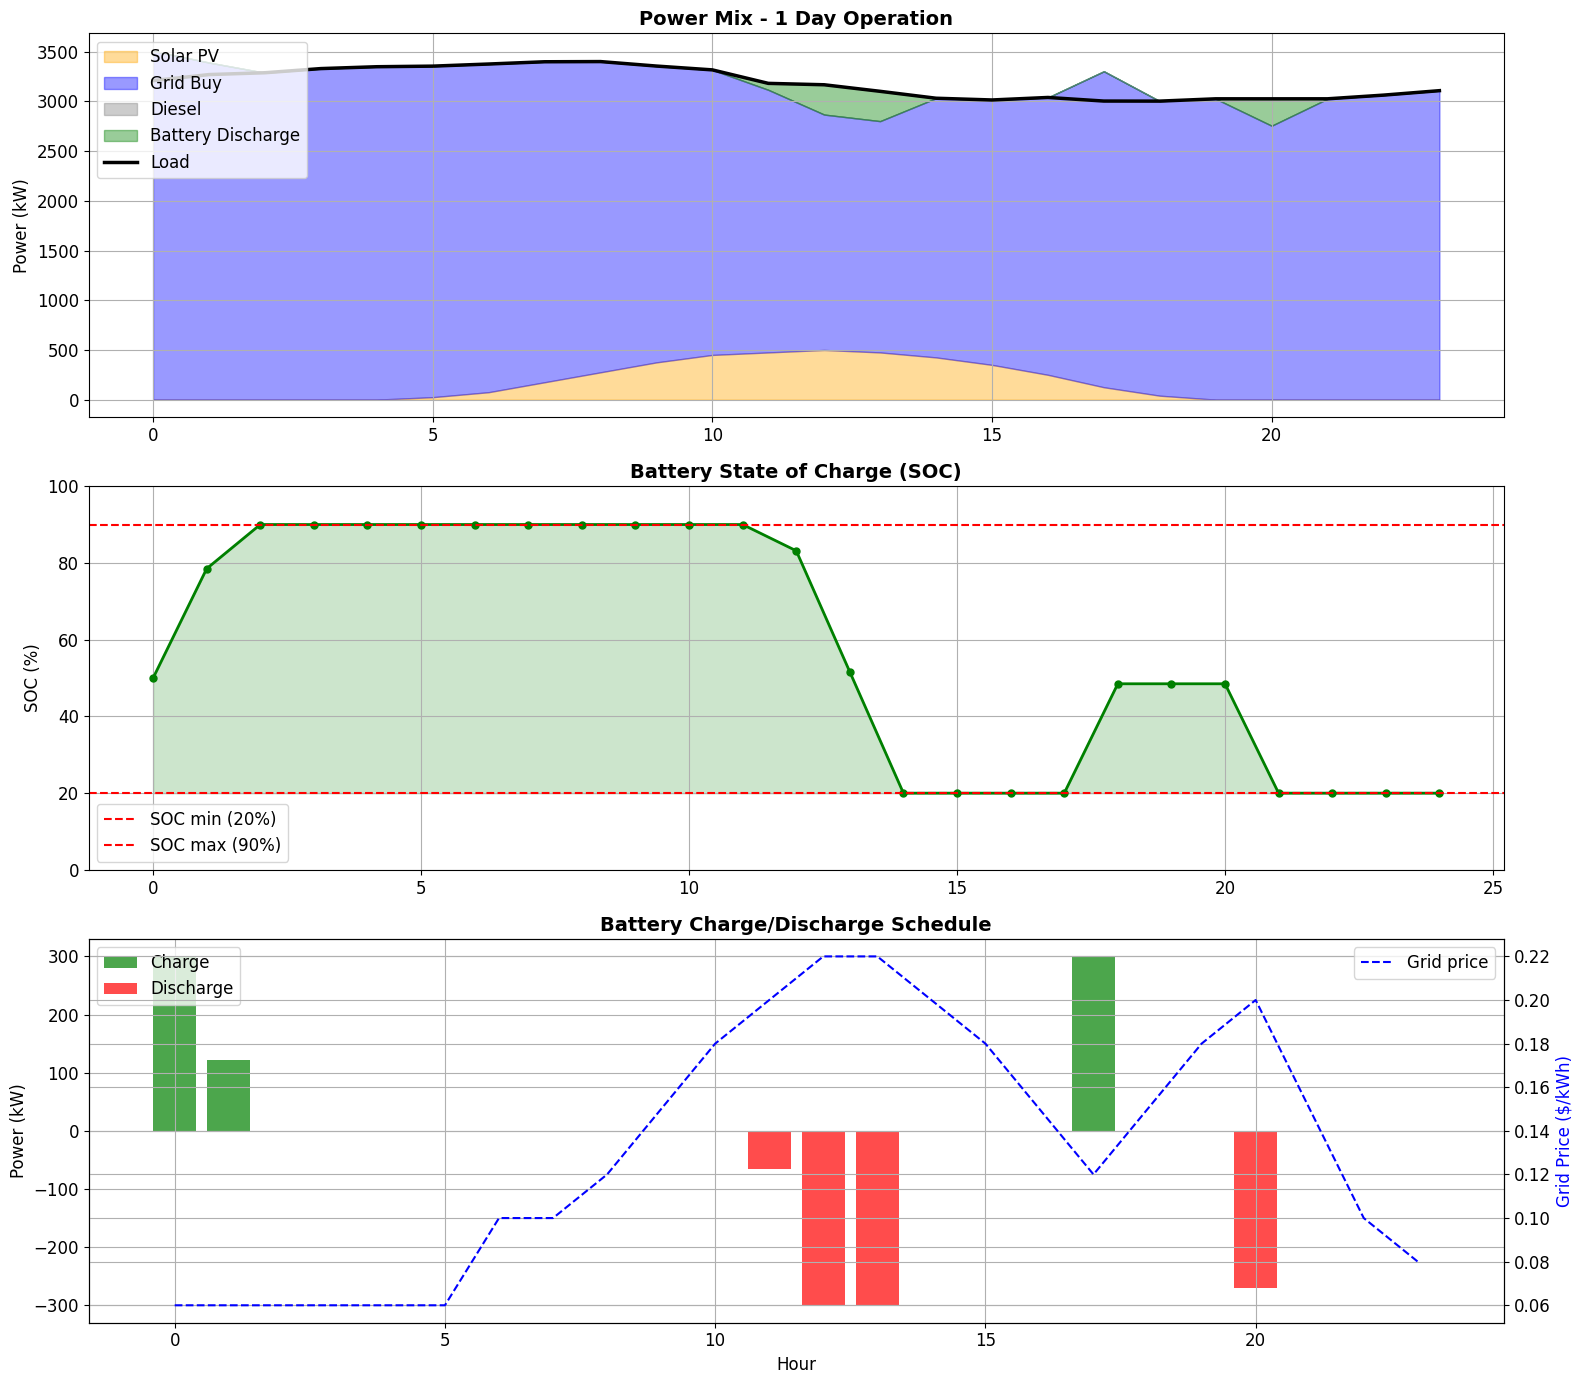

In [8]:
# 1-day detailed operation
res = model_day_results['CNN-BiLSTM-Attention'][0]
hours = range(24)

fig, axes = plt.subplots(3, 1, figsize=(16, 14))

# Panel 1: Power sources stacked
axes[0].fill_between(hours, res['P_solar'], alpha=0.4, color='orange', label='Solar PV')
axes[0].fill_between(hours, res['P_solar'], res['P_solar'] + res['P_grid_buy'], alpha=0.4, color='blue', label='Grid Buy')
axes[0].fill_between(hours, res['P_solar'] + res['P_grid_buy'],
                      res['P_solar'] + res['P_grid_buy'] + res['P_diesel'], alpha=0.4, color='gray', label='Diesel')
axes[0].fill_between(hours, res['P_solar'] + res['P_grid_buy'] + res['P_diesel'],
                      res['P_solar'] + res['P_grid_buy'] + res['P_diesel'] + res['P_bat_discharge'],
                      alpha=0.4, color='green', label='Battery Discharge')
axes[0].plot(hours, res['P_load'], 'k-', linewidth=2.5, label='Load')
axes[0].set_title('Power Mix - 1 Day Operation', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Power (kW)')
axes[0].legend(loc='upper left')

# Panel 2: Battery SOC
axes[1].plot(range(25), res['SOC'] * 100, 'g-o', linewidth=2, markersize=5)
axes[1].axhline(y=SOC_MIN*100, color='r', linestyle='--', label=f'SOC min ({SOC_MIN*100:.0f}%)')
axes[1].axhline(y=SOC_MAX*100, color='r', linestyle='--', label=f'SOC max ({SOC_MAX*100:.0f}%)')
axes[1].fill_between(range(25), SOC_MIN*100, res['SOC']*100, alpha=0.2, color='green')
axes[1].set_title('Battery State of Charge (SOC)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('SOC (%)')
axes[1].set_ylim([0, 100])
axes[1].legend()

# Panel 3: Battery charge/discharge
charge = res['P_bat_charge']
discharge = -res['P_bat_discharge']
colors_bat = ['green' if c > 0 else 'red' for c in charge + discharge]
axes[2].bar(hours, charge, color='green', alpha=0.7, label='Charge')
axes[2].bar(hours, discharge, color='red', alpha=0.7, label='Discharge')
ax2 = axes[2].twinx()
ax2.plot(hours, grid_buy_price, 'b--', linewidth=1.5, label='Grid price')
ax2.set_ylabel('Grid Price ($/kWh)', color='blue')
axes[2].set_title('Battery Charge/Discharge Schedule', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Hour')
axes[2].set_ylabel('Power (kW)')
axes[2].legend(loc='upper left')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'microgrid_operation_detail.png'), dpi=150)
plt.show()

### 5.1 Chiến lược điều khiển pin (Battery Scheduling)

Bài toán LP đã tối ưu lịch sạc/xả pin tự động:
- **Sạc** khi giá điện thấp (off-peak: 0h-6h)
- **Xả** khi giá điện cao (peak: 11h-14h)
- SOC luôn nằm trong giới hạn an toàn [20%-90%]

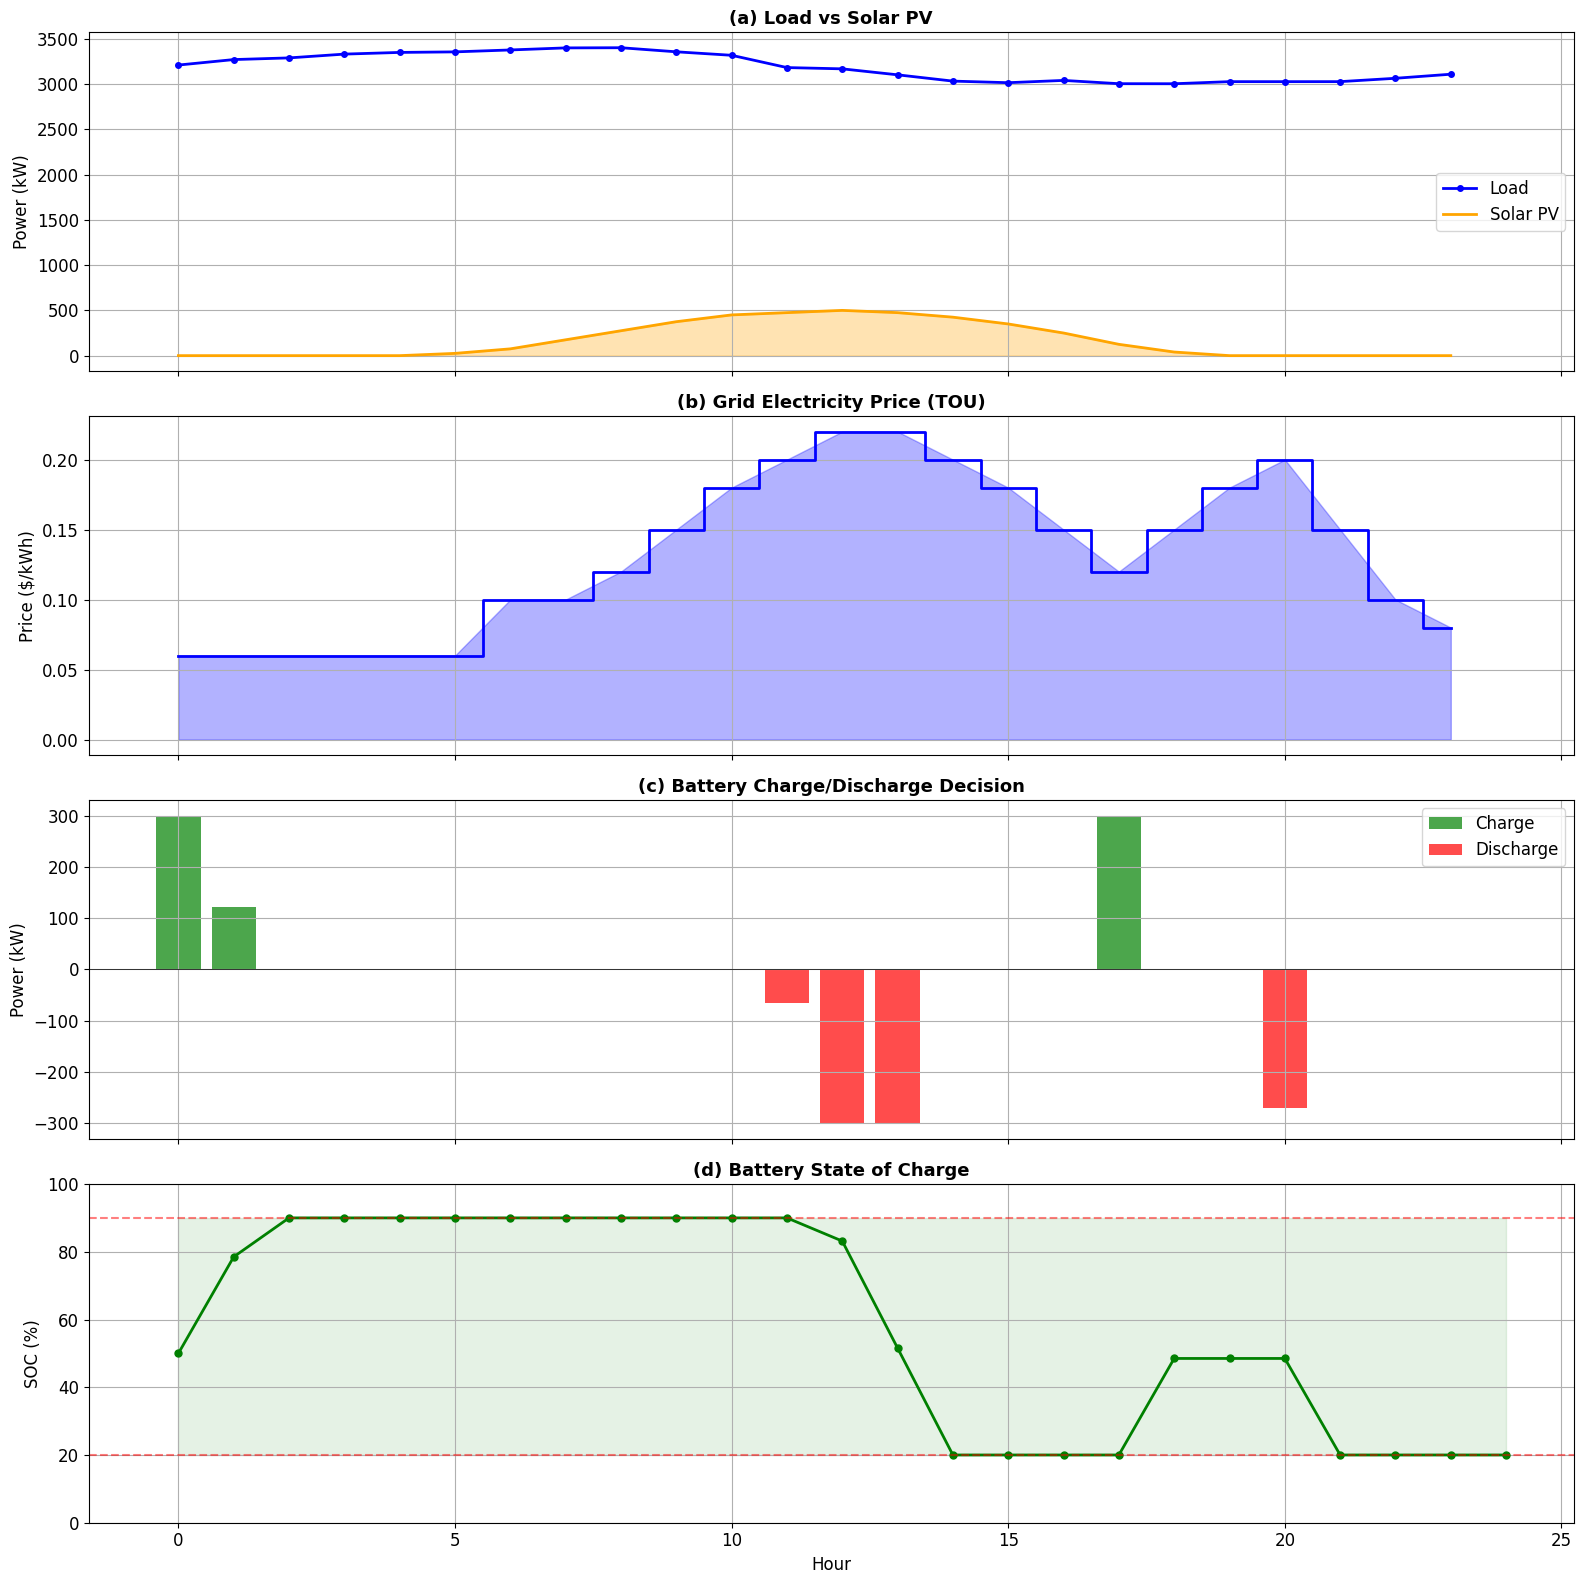

In [9]:
# Battery scheduling strategy visualization
fig, axes = plt.subplots(4, 1, figsize=(16, 16), sharex=True)

hours = range(24)
res = model_day_results['CNN-BiLSTM-Attention'][0]

# 1. Load vs Solar
axes[0].plot(hours, res['P_load'], 'b-o', linewidth=2, label='Load', markersize=4)
axes[0].fill_between(hours, res['P_solar'], alpha=0.3, color='orange')
axes[0].plot(hours, res['P_solar'], 'orange', linewidth=2, label='Solar PV')
axes[0].set_ylabel('Power (kW)')
axes[0].set_title('(a) Load vs Solar PV', fontsize=13, fontweight='bold')
axes[0].legend()

# 2. Grid price
axes[1].fill_between(hours, grid_buy_price, alpha=0.3, color='blue')
axes[1].step(hours, grid_buy_price, 'b-', linewidth=2, where='mid')
axes[1].set_ylabel('Price ($/kWh)')
axes[1].set_title('(b) Grid Electricity Price (TOU)', fontsize=13, fontweight='bold')

# 3. Battery action
axes[2].bar(hours, res['P_bat_charge'], color='green', alpha=0.7, label='Charge')
axes[2].bar(hours, -res['P_bat_discharge'], color='red', alpha=0.7, label='Discharge')
axes[2].axhline(y=0, color='black', linewidth=0.5)
axes[2].set_ylabel('Power (kW)')
axes[2].set_title('(c) Battery Charge/Discharge Decision', fontsize=13, fontweight='bold')
axes[2].legend()

# 4. SOC
axes[3].plot(range(25), res['SOC'] * 100, 'g-o', linewidth=2, markersize=5)
axes[3].axhline(y=SOC_MIN*100, color='r', linestyle='--', alpha=0.5)
axes[3].axhline(y=SOC_MAX*100, color='r', linestyle='--', alpha=0.5)
axes[3].fill_between(range(25), SOC_MIN*100, SOC_MAX*100, alpha=0.1, color='green')
axes[3].set_ylabel('SOC (%)')
axes[3].set_xlabel('Hour')
axes[3].set_title('(d) Battery State of Charge', fontsize=13, fontweight='bold')
axes[3].set_ylim([0, 100])

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'battery_scheduling_strategy.png'), dpi=150)
plt.show()

### 5.2 Phân tích hành vi vận hành pin theo thời gian

Phân tích **trung bình nhiều ngày** để thấy pattern lặp lại.

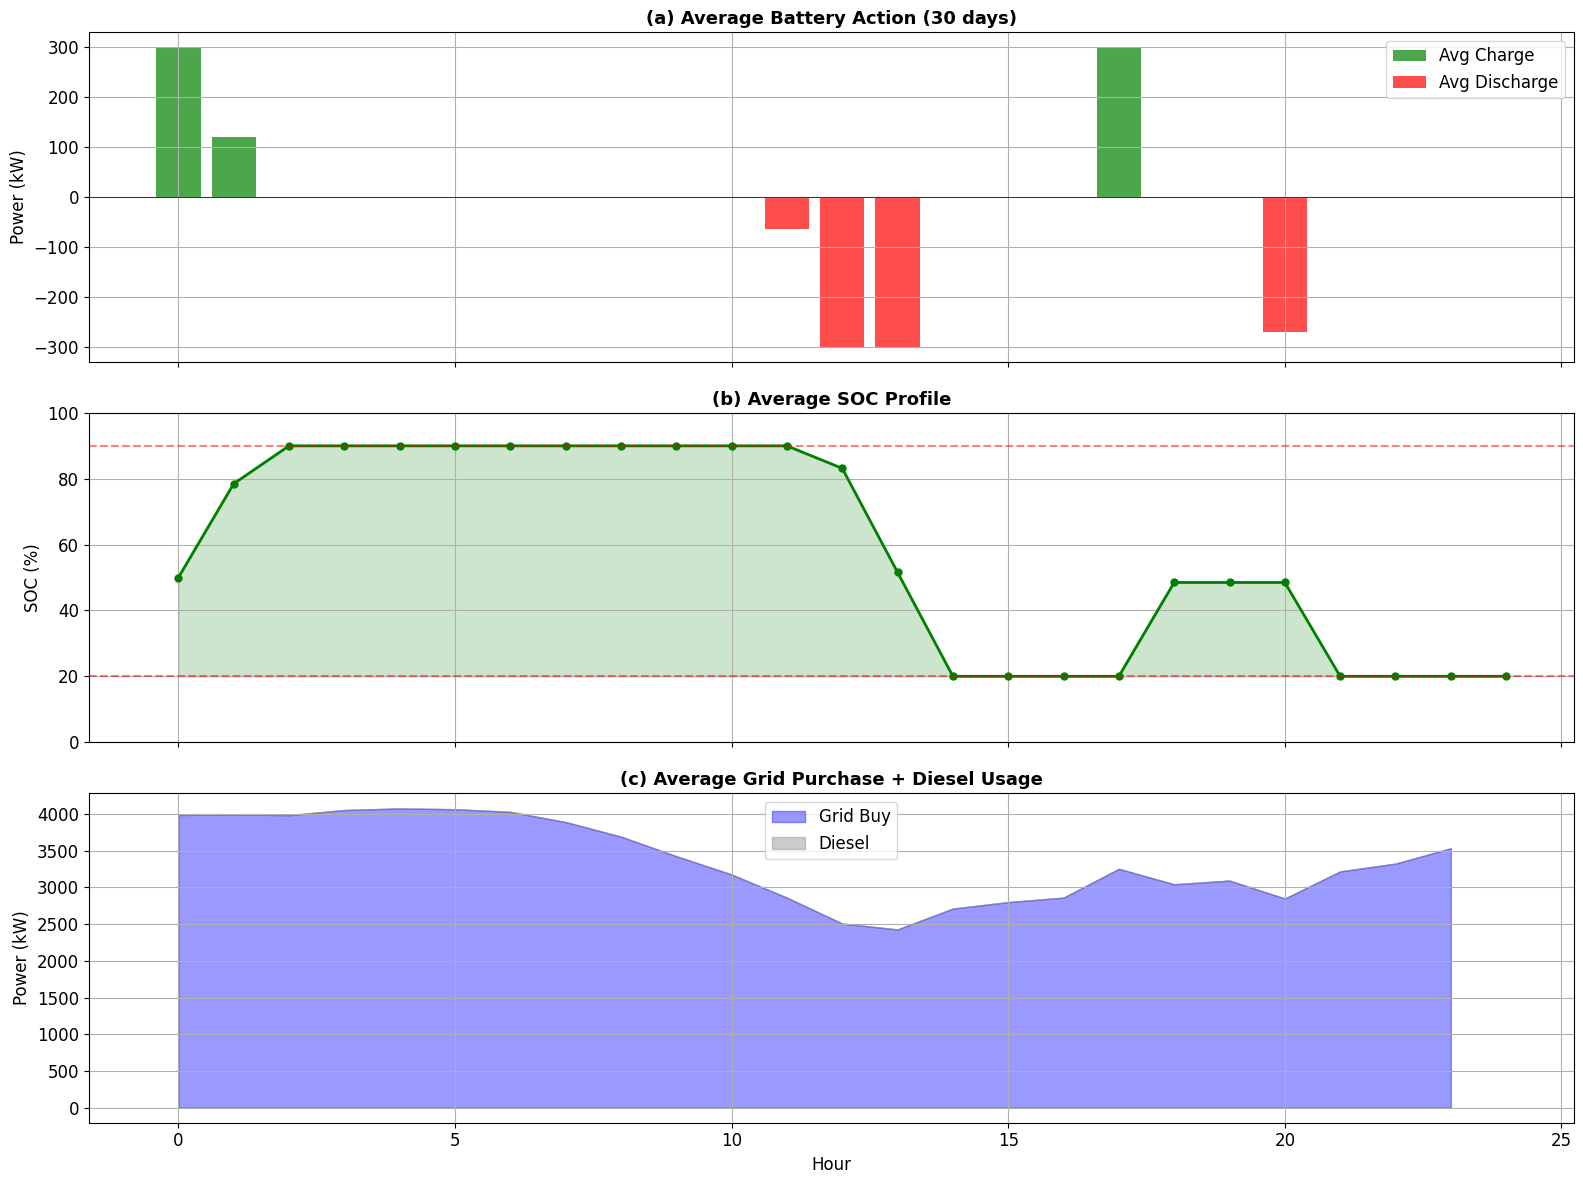

In [10]:
# Average battery behavior across all days
day_results = model_day_results['CNN-BiLSTM-Attention']
n = len(day_results)

avg_charge = np.mean([r['P_bat_charge'] for r in day_results], axis=0)
avg_discharge = np.mean([r['P_bat_discharge'] for r in day_results], axis=0)
avg_soc = np.mean([r['SOC'] for r in day_results], axis=0)
avg_grid_buy = np.mean([r['P_grid_buy'] for r in day_results], axis=0)
avg_diesel = np.mean([r['P_diesel'] for r in day_results], axis=0)

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

hours = range(24)

# 1. Average battery action
axes[0].bar(hours, avg_charge, color='green', alpha=0.7, label='Avg Charge')
axes[0].bar(hours, -avg_discharge, color='red', alpha=0.7, label='Avg Discharge')
axes[0].axhline(y=0, color='black', linewidth=0.5)
axes[0].set_ylabel('Power (kW)')
axes[0].set_title(f'(a) Average Battery Action ({n} days)', fontsize=13, fontweight='bold')
axes[0].legend()

# 2. Average SOC
axes[1].plot(range(25), avg_soc * 100, 'g-o', linewidth=2, markersize=5)
axes[1].fill_between(range(25), SOC_MIN*100, avg_soc*100, alpha=0.2, color='green')
axes[1].axhline(y=SOC_MIN*100, color='r', linestyle='--', alpha=0.5)
axes[1].axhline(y=SOC_MAX*100, color='r', linestyle='--', alpha=0.5)
axes[1].set_ylabel('SOC (%)')
axes[1].set_title('(b) Average SOC Profile', fontsize=13, fontweight='bold')
axes[1].set_ylim([0, 100])

# 3. Average grid buy vs diesel
axes[2].fill_between(hours, avg_grid_buy, alpha=0.4, color='blue', label='Grid Buy')
axes[2].fill_between(hours, avg_grid_buy, avg_grid_buy + avg_diesel, alpha=0.4, color='gray', label='Diesel')
axes[2].set_ylabel('Power (kW)')
axes[2].set_xlabel('Hour')
axes[2].set_title('(c) Average Grid Purchase + Diesel Usage', fontsize=13, fontweight='bold')
axes[2].legend()

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'battery_behavior_analysis.png'), dpi=150)
plt.show()

### 5.3 Tác động của độ chính xác dự báo đến chi phí

So sánh chi phí phát sinh do sai số dự báo giữa các mô hình.

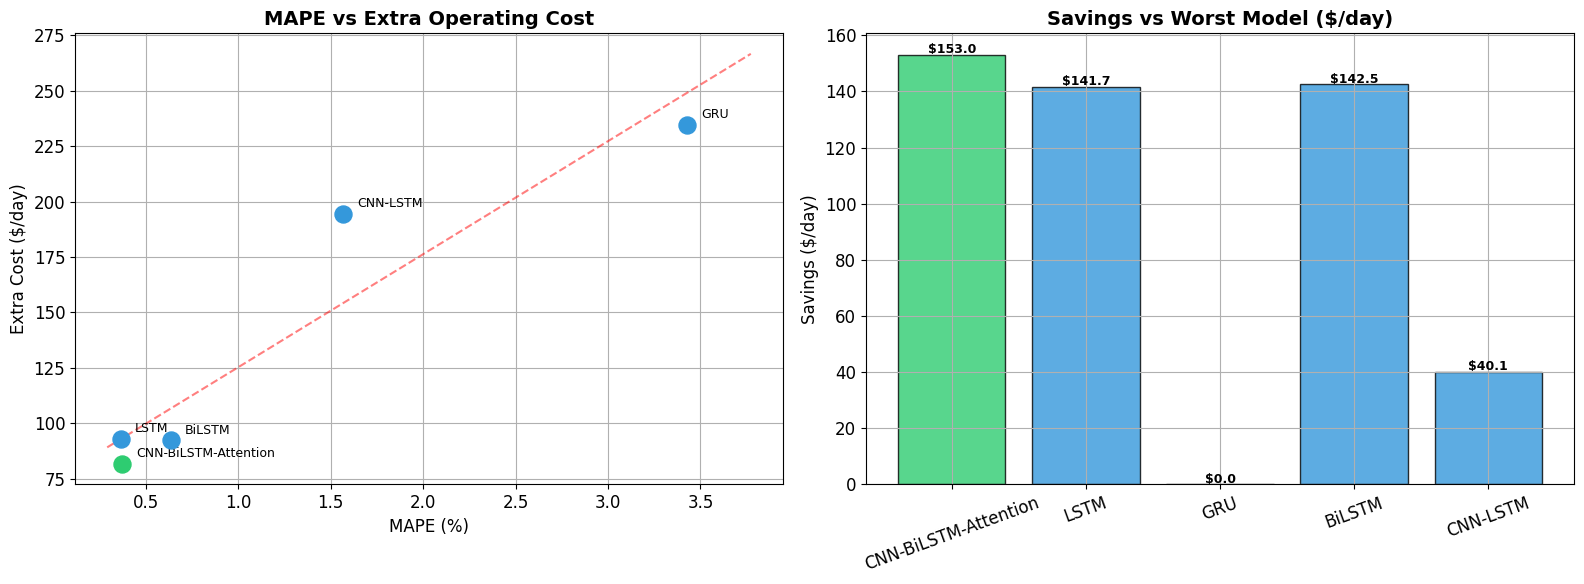

In [11]:
# Forecast accuracy vs cost analysis
from helpers import calculate_metrics

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

model_names = list(all_predictions.keys())
mapes = [calculate_metrics(y_true, all_predictions[m])['MAPE'] for m in model_names]
extra_costs = [cost_results[m] - perfect_cost for m in model_names]

# Scatter: MAPE vs Extra cost
colors = ['#2ecc71' if 'Attention' in m else '#3498db' for m in model_names]
for i, m in enumerate(model_names):
    axes[0].scatter(mapes[i], extra_costs[i], c=colors[i], s=150, zorder=5)
    axes[0].annotate(m, (mapes[i], extra_costs[i]), textcoords='offset points',
                     xytext=(10, 5), fontsize=9)

# Fit line
z = np.polyfit(mapes, extra_costs, 1)
x_line = np.linspace(min(mapes)*0.8, max(mapes)*1.1, 50)
axes[0].plot(x_line, np.polyval(z, x_line), 'r--', alpha=0.5)
axes[0].set_xlabel('MAPE (%)', fontsize=12)
axes[0].set_ylabel('Extra Cost ($/day)', fontsize=12)
axes[0].set_title('MAPE vs Extra Operating Cost', fontsize=14, fontweight='bold')

# Bar: savings vs worst model
worst_cost = max(cost_results.values())
savings = [worst_cost - cost_results[m] for m in model_names]
bars = axes[1].bar(model_names, savings, color=colors, edgecolor='black', alpha=0.8)
axes[1].set_title('Savings vs Worst Model ($/day)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Savings ($/day)')
for bar, s in zip(bars, savings):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f'${s:.1f}', ha='center', fontweight='bold', fontsize=9)
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'forecast_vs_cost_analysis.png'), dpi=150)
plt.show()

## 6. Phân tích hiệu quả kinh tế

=== PHAN TICH HIEU QUA KINH TE ===

Chi phi voi Perfect Forecast: $10034.93/ngay
Chi phi voi CNN-BiLSTM-Attention: $10116.55/ngay
Chenh lech: $81.63/ngay (0.81%)

--- So sanh voi cac model khac ---
CNN-BiLSTM-Attention     : $10116.55/ngay | Proposed saves $0.00/ngay ($0/nam)
LSTM                     : $10127.90/ngay | Proposed saves $11.35/ngay ($4142/nam)
GRU                      : $10269.59/ngay | Proposed saves $153.04/ngay ($55860/nam)
BiLSTM                   : $10127.10/ngay | Proposed saves $10.55/ngay ($3851/nam)
CNN-LSTM                 : $10229.52/ngay | Proposed saves $112.97/ngay ($41233/nam)


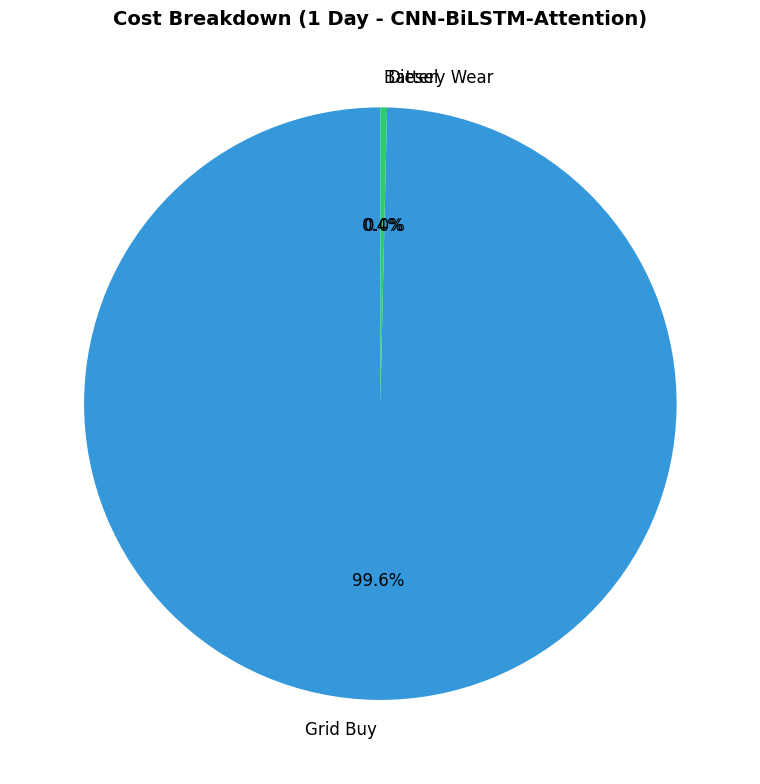


Notebook 06 hoan tat!
=== DU AN HOAN TAT ===


In [12]:
# Economic summary
proposed_cost = cost_results['CNN-BiLSTM-Attention']
print('=== PHAN TICH HIEU QUA KINH TE ===')
print(f'\nChi phi voi Perfect Forecast: ${perfect_cost:.2f}/ngay')
print(f'Chi phi voi CNN-BiLSTM-Attention: ${proposed_cost:.2f}/ngay')
print(f'Chenh lech: ${proposed_cost - perfect_cost:.2f}/ngay ({(proposed_cost - perfect_cost)/perfect_cost*100:.2f}%)')

print(f'\n--- So sanh voi cac model khac ---')
for name in all_predictions:
    c = cost_results[name]
    saving_vs_proposed = c - proposed_cost
    print(f'{name:25s}: ${c:.2f}/ngay | Proposed saves ${saving_vs_proposed:.2f}/ngay (${saving_vs_proposed*365:.0f}/nam)')

# Cost breakdown pie chart
res = model_day_results['CNN-BiLSTM-Attention'][0]
fig, ax = plt.subplots(figsize=(8, 8))
labels = ['Grid Buy', 'Diesel', 'Battery Wear']
values = [res['cost_grid_buy'], res['cost_diesel'], res['cost_battery']]
colors_pie = ['#3498db', '#95a5a6', '#2ecc71']
ax.pie(values, labels=labels, autopct='%1.1f%%', colors=colors_pie, startangle=90,
       textprops={'fontsize': 12})
ax.set_title('Cost Breakdown (1 Day - CNN-BiLSTM-Attention)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'microgrid_cost_breakdown.png'), dpi=150)
plt.show()

print('\nNotebook 06 hoan tat!')
print('=== DU AN HOAN TAT ===')